# LightGBM (Tweedie) — Final Forecasting Engine

This notebook reproduces and evaluates the final forecasting pipeline of the ML engine (`mlengine`) on real data.

The model is a single **LightGBM regressor with a Tweedie objective**. It predicts expected daily unit sales per product from recent sales, calendar, holiday and price features. It was selected after seven modelling stages (see *Modelling journey* in `README.md`). The hurdle, bucketed, pooled and enriched-feature variants did not outperform it.

The pipeline covers:

- feature construction
- training and chronological backtesting
- the recursive 7-day horizon
- inference safeguards
- per-business retraining

**Parity checks:** at each stage, the results are compared with the `mlengine` package and the registered models in `models/`. Exact matches confirm that the notebook and the deployed engine implement the same logic.

**Requirements:** the M5 files in `data/raw/`. A full run takes about 3 minutes.

In [1]:
import datetime as dt
import json
import sys
import time
import warnings
from dataclasses import dataclass

from pathlib import Path

import holidays
import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW = ROOT / "data" / "raw"
REGISTRY = ROOT / "models"
SAMPLES = ROOT / "data" / "processed" / "samples"
sys.path.insert(0, str(ROOT))  # only used to import mlengine for the parity checks

pd.set_option("display.float_format", "{:.4f}".format)
pd.set_option("display.width", 140)
print(f"Project root: {ROOT}")
print(f"numpy {np.__version__} · pandas {pd.__version__} · lightgbm {lgb.__version__}")

Project root: C:\Users\lordk\Desktop\SemProject\SemProject_MLEngine
numpy 2.5.4 · pandas 2.3.3 · lightgbm 4.7.0


## 1. Configuration

These settings define the model. The engine keeps them in `mlengine/config.py`, and changing any of them requires a new model version.

| Setting | Value | Purpose |
| --- | --- | --- |
| Sales lags | 1, 7, 14, 21 days | Capture yesterday's sales and the weekly pattern. These next-day lags gave the largest accuracy gain during research. |
| Rolling windows | mean and std. dev. over 3, 7, 14 days | Summarise recent level and volatility. Windows end on the day before the target, so the target never enters its own features. |
| History requirement | 21 days, at most 3 unrecorded | 21 days is the longest lag. Products with more gaps receive no AI forecast. |
| Objective | Tweedie (variance power 1.1) | Suits non-negative sales that are mostly zero with occasional large values. |

In [2]:
LAG_DAYS = (1, 7, 14, 21)
ROLLING_WINDOWS = (3, 7, 14)
ROLLING_DELAY = 1                      # rolling windows end on the day before the target
LOOKBACK_DAYS = max(LAG_DAYS)          # 21 days of history are needed to build one row
MAX_MISSING_DAYS_IN_LOOKBACK = 3       # more unrecorded days than this -> no AI forecast

# M5 reference windows (day numbers; d_1 = 2011-01-29)
M5_START_DATE = dt.date(2011, 1, 29)
M5_FEATURE_START_DAY = LOOKBACK_DAYS + 1   # d_22: first day with a full 21-day lag
M5_DEV_TRAIN_END = 1885
M5_DEV_VALID = (1886, 1913)                # early-stopping window
M5_BACKTEST = (1914, 1941)                 # held-out backtest (refit on everything before it)
M5_LAST_OBSERVED_DAY = 1941

RANDOM_SEED = 42
LGBM_PARAMS = {
    "objective": "tweedie", "tweedie_variance_power": 1.1, "n_estimators": 1000,
    "learning_rate": 0.05, "num_leaves": 31, "n_jobs": -1, "random_state": RANDOM_SEED, "verbosity": -1,
}
EARLY_STOPPING_ROUNDS = 30

HORIZON = 7                                # candidate multi-day horizon, enabled only if validated

# Own-data (per-business) training
OWN_DATA_VALID_DAYS = 28
OWN_DATA_BACKTEST_DAYS = 28
OWN_DATA_ELIGIBILITY = {"minProducts": 10, "minHistoryDaysPerProduct": LOOKBACK_DAYS,
                        "minStoreHistoryDays": 120, "minObservedProductDays": 4500}


def m5_day_to_date(day):
    return M5_START_DATE + dt.timedelta(days=int(day) - 1)


# Parity: the notebook's recipe must equal the engine's
from mlengine import config as engine_config
assert engine_config.LAG_DAYS == LAG_DAYS and engine_config.ROLLING_WINDOWS == ROLLING_WINDOWS
assert engine_config.LGBM_PARAMS == LGBM_PARAMS and engine_config.OWN_DATA_ELIGIBILITY == OWN_DATA_ELIGIBILITY
assert (engine_config.M5_DEV_VALID, engine_config.M5_BACKTEST) == (M5_DEV_VALID, M5_BACKTEST)
print("Recipe matches mlengine/config.py")

Recipe matches mlengine/config.py


## 2. Data

The reference model uses the [M5 Walmart dataset](https://www.kaggle.com/competitions/m5-forecasting-accuracy), restricted to store CA_1 and the FOODS category: 1,437 products over 1,941 days (2011-01-29 to 2016-05-22).

Sales are held as a **wide matrix**, with one row per product and one column per day. Lags and rolling statistics then become column offsets, so features for every product are computed in a single pass without sampling.

In [3]:
IDENTITY_COLUMNS = ["id", "item_id", "dept_id", "cat_id", "store_id", "state_id"]
EVENT_COLUMNS = ["event_name_1", "event_type_1", "event_name_2", "event_type_2"]


def load_m5_scope(store_id="CA_1", category_id="FOODS"):
    path = RAW / "sales_train_evaluation.csv"
    header = pd.read_csv(path, nrows=0).columns
    day_columns = [c for c in header if c.startswith("d_")]
    dtypes = {c: "category" for c in IDENTITY_COLUMNS} | {c: "uint16" for c in day_columns}
    sales = pd.read_csv(path, dtype=dtypes, low_memory=False)
    scoped = sales.loc[(sales["store_id"] == store_id) & (sales["cat_id"] == category_id)]
    scoped = scoped.sort_values(["item_id", "store_id"], kind="stable").reset_index(drop=True)
    del sales
    identity = pd.DataFrame({c: scoped[c].astype(str).to_numpy() for c in IDENTITY_COLUMNS})
    matrix = scoped[day_columns].to_numpy(dtype="float32", copy=True)

    calendar = pd.read_csv(RAW / "calendar.csv", parse_dates=["date"], low_memory=False,
                           dtype={c: "category" for c in ["d", "weekday", *EVENT_COLUMNS]})

    prices = pd.read_csv(RAW / "sell_prices.csv", low_memory=False, dtype={
        "store_id": "category", "item_id": "category", "wm_yr_wk": "int32", "sell_price": "float32"})
    prices = prices.loc[prices["store_id"].astype(str) == store_id].copy()
    prices["store_id"] = prices["store_id"].astype(str)
    prices["item_id"] = prices["item_id"].astype(str)
    prices = prices.loc[prices["item_id"].isin(set(identity["item_id"]))].reset_index(drop=True)
    assert not prices.duplicated(["store_id", "item_id", "wm_yr_wk"]).any()
    return identity, matrix, calendar, prices


started = time.time()
identity, sales, calendar, prices = load_m5_scope()
n_series, n_days = sales.shape
print(f"Loaded in {time.time() - started:.0f}s: {n_series:,} products × {n_days:,} days "
      f"({m5_day_to_date(1)} to {m5_day_to_date(n_days)})")
print(f"Zero-sales share: {(sales == 0).mean():.1%} · mean units/day: {sales.mean():.2f} · max: {sales.max():.0f}")

Loaded in 13s: 1,437 products × 1,941 days (2011-01-29 to 2016-05-22)
Zero-sales share: 56.9% · mean units/day: 1.96 · max: 648


## 3. Features

### 3.1 Lag and rolling features

The shared function builds these features for both training and inference, so the model receives identically constructed inputs in both cases.

- Each feature uses only observations from before the target day.
- An unrecorded day is `NaN`, not zero. A lag that falls on it, or a rolling window that contains it, is also `NaN`. Missing data is therefore never mistaken for zero sales.

In [4]:
def window_feature_names():
    names = [f"sales_lag_{lag}" for lag in LAG_DAYS]
    for window in ROLLING_WINDOWS:
        names += [f"rolling_mean_{window}", f"rolling_std_{window}"]
    return names


def window_features(sales_matrix, target_columns):
    # Features for every (target column, series) pair, flattened target-major.
    matrix = np.asarray(sales_matrix, dtype=np.float32)
    targets = np.asarray(target_columns, dtype=np.int64)
    assert targets.min() - LOOKBACK_DAYS >= 0, "need 21 days of history before the first target"

    out = {}
    for lag in LAG_DAYS:
        out[f"sales_lag_{lag}"] = matrix[:, targets - lag].T.reshape(-1)

    missing = np.isnan(matrix)
    has_missing = bool(missing.any())
    filled = np.where(missing, np.float32(0), matrix) if has_missing else matrix
    zeros = np.zeros((matrix.shape[0], 1))
    prefix_sum = np.concatenate([zeros, np.cumsum(filled, axis=1, dtype=np.float64)], axis=1)
    prefix_square = np.concatenate([zeros, np.cumsum(filled.astype(np.float64) ** 2, axis=1)], axis=1)
    prefix_missing = (np.concatenate([zeros.astype(np.int64), np.cumsum(missing, axis=1, dtype=np.int64)], axis=1)
                      if has_missing else None)

    for window in ROLLING_WINDOWS:
        window_end = targets - ROLLING_DELAY + 1           # exclusive prefix index: last day is target - 1
        window_start = window_end - window
        window_sum = prefix_sum[:, window_end] - prefix_sum[:, window_start]
        window_square = prefix_square[:, window_end] - prefix_square[:, window_start]
        mean = window_sum / window
        variance = np.maximum((window_square - (window_sum ** 2) / window) / (window - 1), 0.0)
        mean, std = mean.astype("float32"), np.sqrt(variance).astype("float32")
        if prefix_missing is not None:
            gaps = (prefix_missing[:, window_end] - prefix_missing[:, window_start]) > 0
            mean[gaps] = np.nan
            std[gaps] = np.nan
        out[f"rolling_mean_{window}"] = mean.T.reshape(-1)
        out[f"rolling_std_{window}"] = std.T.reshape(-1)
    return out


# A tiny worked example: one series, target = column 21
demo = np.arange(1, 23, dtype=np.float32)[None, :]       # sales 1, 2, ..., 22
print({k: float(v[0]) for k, v in window_features(demo, np.array([21])).items()})

{'sales_lag_1': 21.0, 'sales_lag_7': 15.0, 'sales_lag_14': 8.0, 'sales_lag_21': 1.0, 'rolling_mean_3': 20.0, 'rolling_std_3': 1.0, 'rolling_mean_7': 18.0, 'rolling_std_7': 2.1602468490600586, 'rolling_mean_14': 14.5, 'rolling_std_14': 4.183300018310547}


### 3.2 The full feature row (31 features)

Each row combines the window features with:

- **Product identity:** item, department, category, store and state
- **Calendar:** day and week number, weekday, month, year, day of month and a weekend flag
- **Events:** US event names and types, and California SNAP (food-assistance) days
- **Price:** selling price, a missing-price flag and weeks since the item was first priced

The parity check shows the engine produces identical rows over the 28-day backtest window (40,236 rows). Training and serving therefore use the same feature definitions.

In [5]:
CALENDAR_FEATURE_COLUMNS = ["d_num", "date", "wm_yr_wk", "week_index", "weekday_num", "month_num", "year_num",
                            "day_of_month", "is_weekend", *EVENT_COLUMNS, "snap_CA"]
CATEGORICAL_COLUMNS = IDENTITY_COLUMNS + EVENT_COLUMNS


def build_calendar_features(calendar):
    features = calendar.copy()
    features["d_num"] = features["d"].astype(str).str.removeprefix("d_").astype("int32")
    features["weekday_num"] = features["date"].dt.dayofweek.astype("int8")
    features["month_num"] = features["date"].dt.month.astype("int8")
    features["year_num"] = features["date"].dt.year.astype("int16")
    features["day_of_month"] = features["date"].dt.day.astype("int8")
    features["is_weekend"] = features["weekday_num"].ge(5).astype("int8")
    for column in EVENT_COLUMNS:
        features[column] = features[column].astype("category")
    weeks = sorted(features["wm_yr_wk"].dropna().unique().tolist())
    week_index = {int(week): i for i, week in enumerate(weeks)}
    features["week_index"] = features["wm_yr_wk"].map(week_index).astype("int16")
    return features[CALENDAR_FEATURE_COLUMNS].rename(columns={"snap_CA": "snap"})


def build_release_weeks(prices, calendar_features):
    # First priced week per item: the 'release' proxy behind weeks_since_first_price.
    week_index = calendar_features[["wm_yr_wk", "week_index"]].drop_duplicates().set_index("wm_yr_wk")["week_index"]
    release = (prices.groupby(["store_id", "item_id"], as_index=False)["wm_yr_wk"].min()
               .rename(columns={"wm_yr_wk": "first_price_week"}))
    release["release_week_index"] = release["first_price_week"].map(week_index)
    return release


@dataclass
class M5Context:
    calendar_features: pd.DataFrame
    prices: pd.DataFrame
    release_weeks: pd.DataFrame


def build_m5_frame(identity, sales_matrix, first_day, target_days, context):
    # One row per (target day, series). Column j of sales_matrix is M5 day first_day + j.
    target_days = np.asarray(target_days, dtype=np.int32)
    target_columns = target_days.astype(np.int64) - first_day
    n = len(identity)
    data = {c: np.tile(identity[c].astype(str).to_numpy(dtype=object), len(target_days)) for c in IDENTITY_COLUMNS}
    data["d_num"] = np.repeat(target_days, n).astype("int32")
    data.update(window_features(sales_matrix, target_columns))
    inside = target_columns < sales_matrix.shape[1]
    target_values = np.full((n, len(target_days)), np.nan, dtype=np.float32)
    target_values[:, inside] = sales_matrix[:, target_columns[inside]]
    data["sales"] = target_values.T.reshape(-1)
    frame = pd.DataFrame(data)

    frame = frame.merge(context.calendar_features, on="d_num", how="left", validate="many_to_one")
    frame = frame.merge(context.prices[["store_id", "item_id", "wm_yr_wk", "sell_price"]],
                        on=["store_id", "item_id", "wm_yr_wk"], how="left", validate="many_to_one")
    frame["price_missing"] = frame["sell_price"].isna().astype("int8")
    frame = frame.merge(context.release_weeks[["store_id", "item_id", "release_week_index"]],
                        on=["store_id", "item_id"], how="left", validate="many_to_one")
    frame["weeks_since_first_price"] = (frame["week_index"].astype("float32")
                                        - frame["release_week_index"].astype("float32"))
    frame = frame.drop(columns=["release_week_index", "week_index"])
    for column in CATEGORICAL_COLUMNS:
        frame[column] = frame[column].astype("category")
    return frame


calendar_features = build_calendar_features(calendar)
context = M5Context(calendar_features, prices, build_release_weeks(prices, calendar_features))

started = time.time()
frame = build_m5_frame(identity, sales, 1, np.arange(M5_FEATURE_START_DAY, M5_LAST_OBSERVED_DAY + 1), context)
FEATURES = [c for c in frame.columns if c not in {"sales", "date"}]
print(f"Feature frame: {len(frame):,} rows × {len(FEATURES)} features in {time.time() - started:.0f}s")
print(FEATURES)

Feature frame: 2,759,040 rows × 31 features in 8s
['id', 'item_id', 'dept_id', 'cat_id', 'store_id', 'state_id', 'd_num', 'sales_lag_1', 'sales_lag_7', 'sales_lag_14', 'sales_lag_21', 'rolling_mean_3', 'rolling_std_3', 'rolling_mean_7', 'rolling_std_7', 'rolling_mean_14', 'rolling_std_14', 'wm_yr_wk', 'weekday_num', 'month_num', 'year_num', 'day_of_month', 'is_weekend', 'event_name_1', 'event_type_1', 'event_name_2', 'event_type_2', 'snap', 'sell_price', 'price_missing', 'weeks_since_first_price']


In [6]:
# Parity check: the engine builds exactly the same rows (backtest window, all 31 features)
from mlengine.features import m5_v1 as engine_m5

engine_cal = engine_m5.build_calendar_features(calendar)
engine_context = engine_m5.M5Context(engine_cal, prices, engine_m5.build_release_weeks(prices, engine_cal))
check_days = np.arange(M5_BACKTEST[0], M5_BACKTEST[1] + 1)
pd.testing.assert_frame_equal(build_m5_frame(identity, sales, 1, check_days, context),
                              engine_m5.build_feature_frame(identity, sales, 1, check_days, engine_context))
print(f"Feature parity with mlengine.features.m5_v1: identical over {len(check_days) * n_series:,} rows")

Feature parity with mlengine.features.m5_v1: identical over 40,236 rows


## 4. Baselines and metrics

The AI is evaluated against two baselines:

- **Same as last day** (`naive_last_value`): the most recent recorded day's sales.
- **Same day last week** (`seasonal_naive_7`): sales seven days before the target day.

Metrics:

- **MAE:** mean absolute error, in units.
- **RMSE:** root mean squared error, in units. Large errors weigh more heavily than in MAE.
- **WAPE:** total absolute error divided by total actual sales. Because it is relative, it compares products and groups with different sales volumes.

In [7]:
def _pairs(actual, forecast):
    actual, forecast = np.asarray(actual, dtype=np.float64), np.asarray(forecast, dtype=np.float64)
    keep = ~(np.isnan(actual) | np.isnan(forecast))
    return actual[keep], forecast[keep]


def summary(actual, forecast):
    a, f = _pairs(actual, forecast)
    if not a.size:
        return {"n": 0, "mae": None, "rmse": None, "wape": None}
    return {"n": int(a.size), "mae": float(np.mean(np.abs(a - f))), "rmse": float(np.sqrt(np.mean((a - f) ** 2))),
            "wape": float(np.abs(a - f).sum() / a.sum()) if a.sum() > 0 else None}


def naive_last_value(history, horizon):
    history = np.asarray(history, dtype=np.float32)
    recorded = ~np.isnan(history)
    last_index = np.where(recorded.any(axis=1), history.shape[1] - 1 - np.argmax(recorded[:, ::-1], axis=1), -1)
    last = np.where(last_index >= 0, history[np.arange(len(history)), np.maximum(last_index, 0)], np.nan)
    return np.repeat(last[:, None], horizon, axis=1).astype(np.float32)


def seasonal_naive_7(history, horizon):
    last_week = np.asarray(history, dtype=np.float32)[:, -7:]
    return np.stack([last_week[:, h % 7] for h in range(horizon)], axis=1)


def metrics_table(blocks):
    return pd.DataFrame({name: {k: v for k, v in block.items()} for name, block in blocks.items()}).T

## 5. Training and backtesting

| Model | Trained on | Evaluated on | Role |
| --- | --- | --- | --- |
| Development | d_22 – d_1885 | d_1886 – d_1913 | Early stopping selects the number of trees (70). |
| Backtest | d_22 – d_1913 | **d_1914 – d_1941 (held out)** | Refit with that tree count; gives the accuracy estimate. |
| Production | d_22 – d_1941 | — | Serves real forecasts (section 8). |

Every evaluation window comes after the training data. No future information enters training or model selection.

Evaluation is **one step ahead**: each day is predicted from actual sales up to the previous day.

On the held-out backtest, the AI reaches RMSE 2.377 and MAE 1.377. That compares with RMSE 3.219 / MAE 1.729 for "same as last day" (26.1% lower RMSE) and RMSE 3.179 / MAE 1.748 for "same day last week". The refit reproduces the registered model exactly.

In [8]:
def fit_with_early_stopping(x_train, y_train, x_valid, y_valid):
    model = lgb.LGBMRegressor(**LGBM_PARAMS)
    with warnings.catch_warnings():
        warnings.filterwarnings("ignore", message=".*eval_set.*deprecated")
        model.fit(x_train, y_train, eval_set=[(x_valid, y_valid)], eval_metric="rmse",
                  callbacks=[lgb.early_stopping(EARLY_STOPPING_ROUNDS, verbose=False)])
    return model


def fit_fixed(x, y, n_estimators):
    model = lgb.LGBMRegressor(**{**LGBM_PARAMS, "n_estimators": int(n_estimators)})
    model.fit(x, y)
    return model


day = frame["d_num"]
dev_train = frame.loc[day.between(M5_FEATURE_START_DAY, M5_DEV_TRAIN_END)].reset_index(drop=True)
dev_valid = frame.loc[day.between(*M5_DEV_VALID)].reset_index(drop=True)
backtest = frame.loc[day.between(*M5_BACKTEST)].reset_index(drop=True)
print(f"train {len(dev_train):,} rows · validation {len(dev_valid):,} · backtest {len(backtest):,}")

started = time.time()
dev_model = fit_with_early_stopping(dev_train[FEATURES], dev_train["sales"], dev_valid[FEATURES], dev_valid["sales"])
N_TREES = int(dev_model.best_iteration_ or dev_model.n_estimators)
dev_pred = dev_model.predict(dev_valid[FEATURES], num_iteration=N_TREES)
print(f"Development model: early stopping chose {N_TREES} trees ({time.time() - started:.0f}s)")
metrics_table({"AI (LightGBM Tweedie)": summary(dev_valid["sales"], dev_pred),
               "Same as last day": summary(dev_valid["sales"], dev_valid["sales_lag_1"]),
               "Same day last week": summary(dev_valid["sales"], dev_valid["sales_lag_7"])})

train 2,678,568 rows · validation 40,236 · backtest 40,236


Development model: early stopping chose 70 trees (14s)


,n,mae,rmse,wape
AI (LightGBM Tweedie),40236.0000,1.3085,2.3555,0.6218
Same as last day,40236.0000,1.6237,3.1939,0.7716
Same day last week,40236.0000,1.6745,3.2754,0.7958


In [9]:
started = time.time()
before_backtest = pd.concat([dev_train, dev_valid], ignore_index=True)
bt_model = fit_fixed(before_backtest[FEATURES], before_backtest["sales"], N_TREES)
del before_backtest
bt_pred = bt_model.predict(backtest[FEATURES])
print(f"Backtest model refit in {time.time() - started:.0f}s. One-step-ahead backtest, "
      f"{m5_day_to_date(M5_BACKTEST[0])} to {m5_day_to_date(M5_BACKTEST[1])}:")
bt_blocks = {"AI (LightGBM Tweedie)": summary(backtest["sales"], bt_pred),
             "Same as last day": summary(backtest["sales"], backtest["sales_lag_1"]),
             "Same day last week": summary(backtest["sales"], backtest["sales_lag_7"])}
bt_table = metrics_table(bt_blocks)
ai_rmse, naive_rmse = bt_blocks["AI (LightGBM Tweedie)"]["rmse"], bt_blocks["Same as last day"]["rmse"]
print(f"AI RMSE is {1 - ai_rmse / naive_rmse:.1%} lower than 'same as last day'")
bt_table

Backtest model refit in 12s. One-step-ahead backtest, 2016-04-25 to 2016-05-22:
AI RMSE is 26.1% lower than 'same as last day'


,n,mae,rmse,wape
AI (LightGBM Tweedie),40236.0000,1.3766,2.3773,0.6098
Same as last day,40236.0000,1.7285,3.2186,0.7657
Same day last week,40236.0000,1.7481,3.1793,0.7744


In [10]:
# Parity check: compare with the backtest stored with the registered model m5-ca1-foods@1.1.0
stored = json.loads((REGISTRY / "m5-ca1-foods" / "1.1.0" / "backtest" / "summary.json").read_text())
stored_trees = json.loads((REGISTRY / "m5-ca1-foods" / "1.1.0" / "metadata.json").read_text())["params"]["n_estimators"]
comparison = pd.DataFrame({
    "this notebook": [N_TREES, bt_blocks["AI (LightGBM Tweedie)"]["rmse"], bt_blocks["AI (LightGBM Tweedie)"]["mae"],
                      bt_blocks["Same as last day"]["rmse"]],
    "registered model 1.1.0": [stored_trees, stored["ai"]["rmse"], stored["ai"]["mae"], stored["naive_last_value"]["rmse"]],
}, index=["trees", "AI backtest RMSE", "AI backtest MAE", "Naive backtest RMSE"])
comparison["difference"] = comparison["this notebook"] - comparison["registered model 1.1.0"]
comparison

,this notebook,registered model 1.1.0,difference
trees,70.0000,70.0000,0.0000
AI backtest RMSE,2.3773,2.3773,0.0000
AI backtest MAE,1.3766,1.3766,0.0000
Naive backtest RMSE,3.2186,3.2186,0.0000


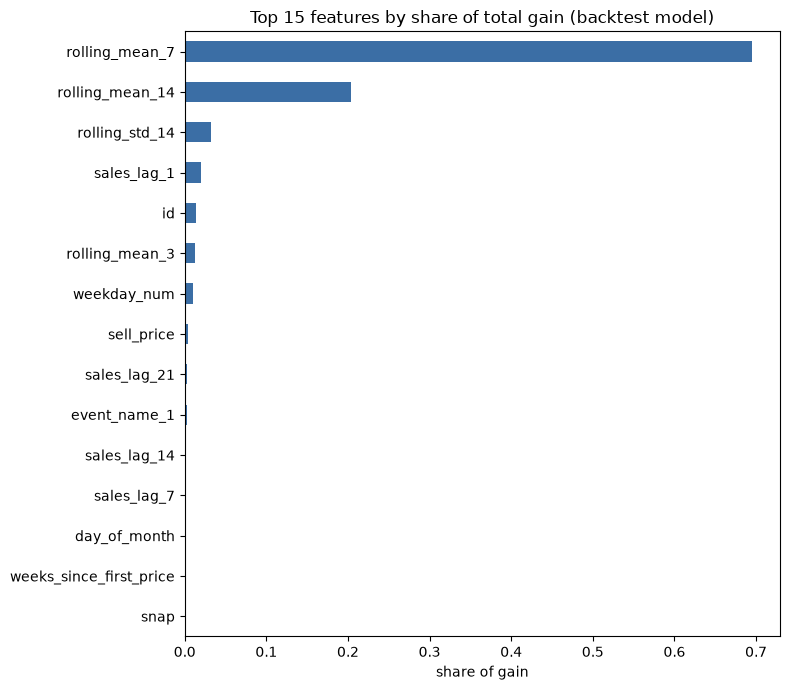

In [11]:
importance = pd.Series(bt_model.booster_.feature_importance("gain"), index=FEATURES).sort_values()
importance = importance / importance.sum()
fig, ax = plt.subplots(figsize=(8, 7))
importance.tail(15).plot.barh(ax=ax, color="#3b6ea5")
ax.set_title("Top 15 features by share of total gain (backtest model)")
ax.set_xlabel("share of gain")
plt.tight_layout()
plt.show()

## 6. Error by demand class

Products are classified with the Syntetos–Boylan scheme, using the 365 days before the backtest:

- **ADI** (average demand interval): recorded days divided by days with sales. It measures how often a product sells.
- **CV²**: the squared coefficient of variation of the non-zero sales. It measures how much the quantities sold vary.

| Class | ADI < 1.32 (sells often) | ADI ≥ 1.32 (sells on some days only) |
| --- | --- | --- |
| **CV² < 0.49** (stable quantities) | Smooth | Intermittent |
| **CV² ≥ 0.49** (variable quantities) | Erratic | Lumpy |

Products with fewer than 30 recorded days or fewer than 5 days with sales are labelled `INSUFFICIENT_DATA`.

The AI beats "same as last day" in every class, by 21.3% to 28.6% RMSE. Relative error varies widely, though:

- **Smooth:** WAPE 40.1%
- **Erratic:** WAPE 51.1%
- **Intermittent:** WAPE 76.4%
- **Lumpy:** WAPE 85.4%

Raw RMSE is highest for smooth and erratic products only because they sell more units. A product's demand class therefore indicates how much confidence an individual forecast deserves, which is why the app displays it.

In [12]:
ADI_CUTOFF, CV2_CUTOFF = 1.32, 0.49


def demand_class(history, window=365):
    values = np.asarray(history, dtype=np.float64)[-window:]
    values = values[~np.isnan(values)]
    positive = values[values > 0]
    if values.size < 30 or positive.size < 5:
        return "INSUFFICIENT_DATA"
    adi = values.size / positive.size
    cv2 = (positive.std(ddof=1) / positive.mean()) ** 2
    if adi < ADI_CUTOFF:
        return "SMOOTH" if cv2 < CV2_CUTOFF else "ERRATIC"
    return "INTERMITTENT" if cv2 < CV2_CUTOFF else "LUMPY"


classes = pd.Series([demand_class(row) for row in sales[:, : M5_BACKTEST[0] - 1]], index=identity["item_id"])
scored = pd.DataFrame({"item_id": backtest["item_id"].astype(str), "actual": backtest["sales"], "ai": bt_pred,
                       "naive": backtest["sales_lag_1"], "seasonal": backtest["sales_lag_7"]})
scored["class"] = scored["item_id"].map(classes)
rows = []
for name, group in scored.groupby("class"):
    ai, naive = summary(group["actual"], group["ai"]), summary(group["actual"], group["naive"])
    rows.append({"class": name, "products": group["item_id"].nunique(), "AI RMSE": ai["rmse"],
                 "AI WAPE": ai["wape"], "naive RMSE": naive["rmse"], "AI better than naive by": 1 - ai["rmse"] / naive["rmse"]})
by_class = pd.DataFrame(rows).set_index("class")
by_class.style.format({"AI RMSE": "{:.3f}", "AI WAPE": "{:.1%}", "naive RMSE": "{:.3f}", "AI better than naive by": "{:.1%}"})

,products,AI RMSE,AI WAPE,naive RMSE,AI better than naive by
class,,,,,
ERRATIC,37,5.156,51.1%,6.555,21.3%
INSUFFICIENT_DATA,5,1.690,88.5%,2.204,23.3%
INTERMITTENT,925,1.583,76.4%,2.115,25.2%
LUMPY,249,2.643,85.4%,3.542,25.4%
SMOOTH,221,3.725,40.1%,5.215,28.6%


## 7. The 7-day horizon

The model predicts one day ahead, so longer forecasts are built recursively:

1. Day 1 is predicted from actual history.
2. That prediction is written into a temporary copy of the sales matrix.
3. Features are rebuilt and day 2 is predicted, and so on up to day 7.

From day 2 onward, the lag and rolling features mix actual observations with earlier predictions. Predicted values stay in the temporary copy and are never stored as sales or used for training. Prices for the forecast days come from the price table where known; otherwise the last known price is carried forward.

Because errors can compound across steps, the horizon is enabled only after a **recursive backtest**. It makes 7-day forecasts from 22 origins across the backtest window (221,298 scored values). The AI must beat **both** baselines on overall RMSE **and** MAE.

Results:

- **Validated.** RMSE rises gradually from 2.337 on day 1 to 2.580 on day 7, staying below both baselines on every day (3.257 for both baselines on day 7).
- **Slight upward bias.** Days 2–7 over-forecast by about 0.08–0.09 units per day on average.

In [13]:
def recursive_forecast_m5(predict, origin_day, horizon, rows=None):
    # Forecast days origin_day+1 ... origin_day+horizon from actual sales up to origin_day.
    rows = np.arange(n_series) if rows is None else np.asarray(rows)
    first_day = origin_day - LOOKBACK_DAYS + 1                 # only the last 21 days are needed
    work = np.full((len(rows), LOOKBACK_DAYS + horizon), np.nan, dtype=np.float32)
    work[:, :LOOKBACK_DAYS] = sales[rows, first_day - 1 : origin_day]
    for h in range(horizon):
        target = origin_day + 1 + h
        step = build_m5_frame(identity.iloc[rows].reset_index(drop=True), work, first_day, np.array([target]), context)
        work[:, LOOKBACK_DAYS + h] = np.maximum(np.asarray(predict(step[FEATURES]), dtype=np.float32), 0)
    return work[:, LOOKBACK_DAYS:]


def recursive_backtest(predict, history, origins, horizon, forecast):
    ai, naive, seasonal, actual = [], [], [], []
    for origin in origins:                                     # origin = last observed day (1-based)
        ai.append(forecast(predict, origin, horizon))
        naive.append(naive_last_value(history[:, :origin], horizon))
        seasonal.append(seasonal_naive_7(history[:, :origin], horizon))
        actual.append(history[:, origin : origin + horizon])
    ai, naive, seasonal, actual = (np.stack(x) for x in (ai, naive, seasonal, actual))
    keep = ~np.isnan(ai) & ~np.isnan(naive) & ~np.isnan(actual)
    methods = {"ai": ai, "naive_last_value": naive, "seasonal_naive_7": seasonal}
    overall = {name: summary(actual[keep], values[keep]) for name, values in methods.items()}
    by_day = pd.DataFrame([{"day": h + 1, **{f"{name} RMSE": summary(actual[:, :, h][keep[:, :, h]],
                                                                       values[:, :, h][keep[:, :, h]])["rmse"]
                                              for name, values in methods.items()},
                            "AI mean bias": float(np.nanmean(np.where(keep[:, :, h], ai[:, :, h] - actual[:, :, h], np.nan)))}
                           for h in range(horizon)]).set_index("day")
    validated = all(overall["ai"][m] < overall[b][m] for b in ["naive_last_value", "seasonal_naive_7"] for m in ["rmse", "mae"])
    return {"overall": overall, "by_day": by_day, "validated": validated, "origins": len(ai)}


ORIGINS = range(M5_BACKTEST[0] - 1, M5_BACKTEST[1] - HORIZON + 1)
started = time.time()
recursive = recursive_backtest(bt_model.predict, sales, ORIGINS, HORIZON, recursive_forecast_m5)
print(f"{recursive['origins']} origins × {n_series:,} products × {HORIZON} days in {time.time() - started:.0f}s")
print(f"7-day horizon validated: {recursive['validated']}  "
      f"(rule: AI beats both baselines on overall RMSE and MAE)")
display(metrics_table(recursive["overall"]))
recursive["by_day"]

22 origins × 1,437 products × 7 days in 45s
7-day horizon validated: True  (rule: AI beats both baselines on overall RMSE and MAE)


,n,mae,rmse,wape
ai,221298.0000,1.4580,2.4722,0.6391
naive_last_value,221298.0000,1.8601,3.4891,0.8154
seasonal_naive_7,221298.0000,1.7603,3.1756,0.7716


,ai RMSE,naive_last_value RMSE,seasonal_naive_7 RMSE,AI mean bias
day,,,,
1,2.3371,3.1941,3.1148,-0.0115
2,2.3958,3.5068,3.1322,0.0919
3,2.4691,3.6985,3.1700,0.0883
4,2.4821,3.7381,3.1680,0.0804
5,2.5044,3.6137,3.1782,0.0859
6,2.5291,3.3760,3.2070,0.0895
7,2.5799,3.2570,3.2570,0.0805


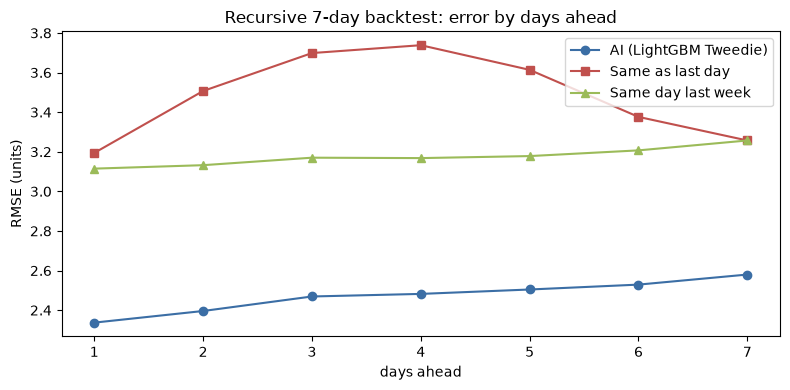

In [14]:
by_day = recursive["by_day"]
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(by_day.index, by_day["ai RMSE"], marker="o", label="AI (LightGBM Tweedie)", color="#3b6ea5")
ax.plot(by_day.index, by_day["naive_last_value RMSE"], marker="s", label="Same as last day", color="#c0504d")
ax.plot(by_day.index, by_day["seasonal_naive_7 RMSE"], marker="^", label="Same day last week", color="#9bbb59")
ax.set_xlabel("days ahead")
ax.set_ylabel("RMSE (units)")
ax.set_title("Recursive 7-day backtest: error by days ahead")
ax.legend()
plt.tight_layout()
plt.show()

In [15]:
# Parity check 1: the stored recursive evaluation of the registered model
stored_recursive = json.loads((REGISTRY / "m5-ca1-foods" / "1.1.0" / "metadata.json").read_text())["evaluation"]["recursive"]
pd.DataFrame({"this notebook": recursive["by_day"]["ai RMSE"].to_numpy(),
              "registered 1.1.0": [d["ai"]["rmse"] for d in stored_recursive["byDay"]]},
             index=pd.Index(range(1, HORIZON + 1), name="day")).assign(
    difference=lambda t: t["this notebook"] - t["registered 1.1.0"])

,this notebook,registered 1.1.0,difference
day,,,
1,2.3371,2.3371,0.0000
2,2.3958,2.3958,0.0000
3,2.4691,2.4691,0.0000
4,2.4821,2.4821,0.0000
5,2.5044,2.5044,0.0000
6,2.5291,2.5291,0.0000
7,2.5799,2.5799,0.0000


In [16]:
# Parity check 2: same booster, same origin -> the notebook's recursion equals mlengine's Forecaster
from mlengine.data.m5 import M5Scope, scope_to_batch
from mlengine.models.artifact import load_artifact
from mlengine.models.forecaster import Forecaster

artifact = load_artifact(REGISTRY / "m5-ca1-foods" / "1.1.0-bt")
scope = M5Scope("CA_1", "FOODS", identity, sales, calendar, prices)
origin = M5_BACKTEST[0] - 1
engine_forecast = Forecaster(artifact).forecast(scope_to_batch(scope, origin, 365, HORIZON), HORIZON).ai
notebook_forecast = recursive_forecast_m5(artifact.booster.predict, origin, HORIZON)
print(f"Max absolute difference over {engine_forecast.size:,} forecast values: "
      f"{np.nanmax(np.abs(engine_forecast - notebook_forecast)):.2e}")
assert np.allclose(engine_forecast, notebook_forecast, atol=1e-4)

Max absolute difference over 10,059 forecast values: 0.00e+00


## 8. The production model

The production model is trained on every observed day up to d_1941 (2016-05-22). It forecasts the following 7 days: 2016-05-23 to 2016-05-29.

The registry's **leakage rule** allows a model version to be used only when the forecast's as-of date is on or after the last day of its training data. This version therefore serves forecasts from 2016-05-22 onward, while earlier as-of dates use the `-dev` or `-bt` versions.

In [17]:
started = time.time()
prod_model = fit_fixed(frame[FEATURES], frame["sales"], N_TREES)
print(f"Production model: {len(frame):,} rows, {N_TREES} trees, {time.time() - started:.0f}s")

future = recursive_forecast_m5(prod_model.predict, M5_LAST_OBSERVED_DAY, HORIZON)
registered = recursive_forecast_m5(load_artifact(REGISTRY / "m5-ca1-foods" / "1.1.0").booster.predict,
                                   M5_LAST_OBSERVED_DAY, HORIZON)
print(f"Mean absolute difference from the registered 1.1.0 model: {np.mean(np.abs(future - registered)):.4f} units")

dates = [m5_day_to_date(M5_LAST_OBSERVED_DAY + h + 1) for h in range(HORIZON)]
top = np.argsort(-sales[:, -28:].sum(axis=1))[:5]
pd.DataFrame(future[top], index=identity["item_id"].iloc[top], columns=[d.strftime("%a %d %b") for d in dates]).round(2)

Production model: 2,759,040 rows, 70 trees, 10s


Mean absolute difference from the registered 1.1.0 model: 0.0000 units


,Mon 23 May,Tue 24 May,Wed 25 May,Thu 26 May,Fri 27 May,Sat 28 May,Sun 29 May
item_id,,,,,,,
FOODS_3_090,48.1600,44.5100,46.8500,47.7000,62.2200,74.0800,75.5700
FOODS_3_120,41.1900,36.1500,32.8700,32.8700,45.3800,59.0000,65.2400
FOODS_3_586,36.0500,33.9900,32.5000,32.9500,41.4400,48.7000,52.4200
FOODS_3_252,35.1000,31.6400,26.8400,26.3600,32.7100,50.6900,54.3100
FOODS_3_064,21.1700,21.2600,19.1000,19.1300,23.4000,28.8200,29.1900


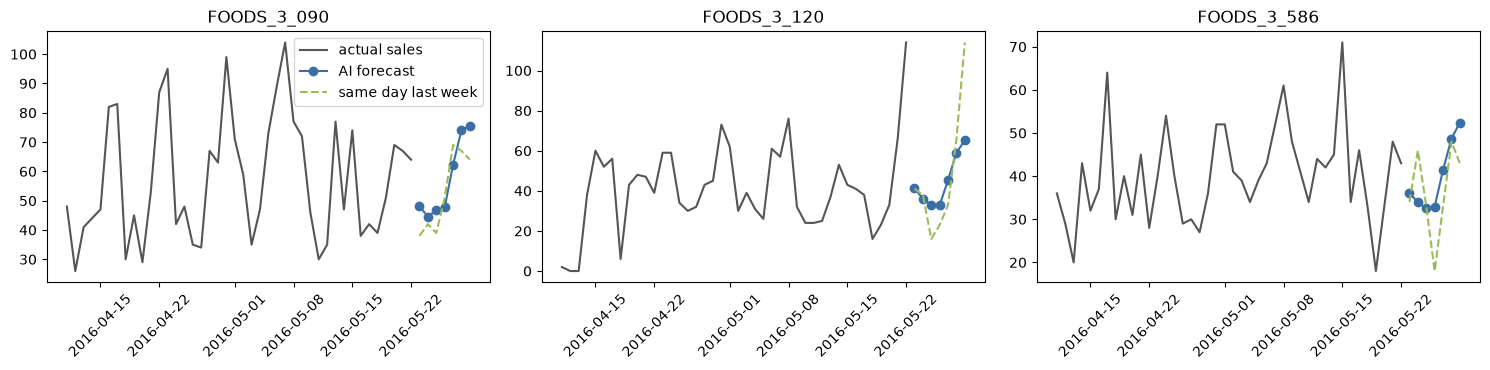

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8), sharey=False)
history_days = 42
for ax, row in zip(axes, top[:3]):
    hist_dates = [m5_day_to_date(d) for d in range(M5_LAST_OBSERVED_DAY - history_days + 1, M5_LAST_OBSERVED_DAY + 1)]
    ax.plot(hist_dates, sales[row, -history_days:], color="#555", label="actual sales")
    ax.plot(dates, future[row], marker="o", color="#3b6ea5", label="AI forecast")
    ax.plot(dates, seasonal_naive_7(sales[row:row + 1], HORIZON)[0], ls="--", color="#9bbb59", label="same day last week")
    ax.set_title(identity["item_id"].iloc[row])
    ax.tick_params(axis="x", rotation=45)
axes[0].legend()
plt.tight_layout()
plt.show()

## 9. Inference safeguards

**Mechanisms that prevent invalid forecasts** (in the engine's `Forecaster` and ML service):

| Situation | Outcome |
| --- | --- |
| Fewer than 21 days of history | No AI forecast (`INSUFFICIENT_HISTORY`) |
| More than 3 unrecorded days in the last 21 | No AI forecast (`TOO_MANY_GAPS`) |
| Product not in the reference model | No AI forecast (`PRODUCT_NOT_IN_MODEL`) |
| Negative prediction | Clipped to 0 |
| Horizon not validated for the model | Request refused (`HORIZON_NOT_SUPPORTED`) |

The code below demonstrates the first two checks and the non-negative clipping.

**Mechanisms that help users interpret forecasts:** the baselines are returned alongside the AI forecast and remain available when the AI is withheld. They act only as a reference and do not constrain the model's output.

**Upper limit:** there is none. Tree ensembles extrapolate poorly beyond the training data, which makes extreme values less likely. However, the Tweedie objective's log link means a prediction can still exceed any value observed in training.

In [19]:
def ai_availability(history):
    # The engine's per-product checks on the 21 days ending on the as-of day (NaN = unrecorded).
    history = np.asarray(history, dtype=np.float32)
    recorded = np.flatnonzero(~np.isnan(history))
    if recorded.size == 0 or history.size - recorded[0] < LOOKBACK_DAYS:
        return "INSUFFICIENT_HISTORY"
    if np.isnan(history[-LOOKBACK_DAYS:]).sum() > MAX_MISSING_DAYS_IN_LOOKBACK:
        return "TOO_MANY_GAPS"
    return "OK"


example = sales[top[0], :M5_LAST_OBSERVED_DAY].copy()
with_gaps = example.copy()
with_gaps[-10:-6] = np.nan                       # 4 unrecorded days in the lookback
print("Full history          ->", ai_availability(example))
print("Only 14 days recorded ->", ai_availability(example[-14:]))
print("4 gaps in last 21     ->", ai_availability(with_gaps))
print(f"Lowest value in the production 7-day forecast: {future.min():.4f} (never negative)")

Full history          -> OK
Only 14 days recorded -> INSUFFICIENT_HISTORY
4 gaps in last 21     -> TOO_MANY_GAPS
Lowest value in the production 7-day forecast: 0.0781 (never negative)


## 10. Retraining on a business's own data

The M5 model only covers Walmart products. For a real business, the same recipe is trained on that business's own sales, with M5-specific inputs replaced (schema `portable-v1`):

| M5 input | Replacement |
| --- | --- |
| M5 identity columns | product, category and store |
| M5 day and week numbers | days since the start of the history |
| US events and SNAP days | the country's public holidays |
| Weekly Walmart price | daily price, with the last known price carried forward |

Lags, rolling windows and calendar fields are unchanged.

**Training stages:**

1. **Eligibility:** at least 10 products with 21+ days of history, 120 days of store history and 4,500 recorded product-days.
2. **Chronological split:** training data, then 28 days for early stopping, then the final 28 days as the one-step-ahead backtest.
3. **Promotion gate:** the model is registered only if its backtest RMSE **and** MAE are both below "same as last day". If it fails, nothing is registered and the business keeps its previous model or the baselines.
4. **Horizon validation:** a separate recursive 7-day test (section 7) decides whether 7-day forecasts are offered. A model can pass the gate and still be limited to next-day forecasts.
5. **Final fit:** refit on all data with the early-stopped tree count, then register it as a new version.

**When retraining happens:** the backend schedules it automatically for workspaces that already have a trained model. It runs when the sales history has changed and at least 7 days have passed since the last run. Training uses only recorded sales, never earlier forecasts, so the model cannot learn from its own errors.

**Example data:** `sample_shop_eligible.csv` contains 100 real Walmart products over 365 days, with the dates shifted forward. As in the import wizard's "no row means zero sales" option, missing days are filled with zero from each product's first recorded day onward.

**Results on the example data:**

- **Gate passed** with 45 trees: AI RMSE 2.063 / MAE 1.213, against 2.612 / 1.429 for "same as last day".
- **7-day horizon validated:** RMSE goes from 1.986 on day 1 to 2.152 on day 7, against 2.803 for both baselines on day 7.
- **Parity:** all of these results match `mlengine.train_own_data`.

In [20]:
def holiday_names(dates, country, subdivision=None):
    if not country or len(dates) == 0:
        return np.full(len(dates), "none", dtype=object)
    table = holidays.country_holidays(country, subdiv=subdivision, years=range(dates.year.min(), dates.year.max() + 1))
    table = {d: name.split(";")[0].strip() for d, name in table.items()}
    return np.array([table.get(d.date(), "none") for d in dates], dtype=object)


def forward_fill_prices(price_matrix):
    prices = np.asarray(price_matrix, dtype=np.float32)
    valid = ~np.isnan(prices)
    index = np.where(valid, np.arange(prices.shape[1]), 0)
    np.maximum.accumulate(index, axis=1, out=index)
    filled = prices[np.arange(prices.shape[0])[:, None], index]
    filled[~np.maximum.accumulate(valid, axis=1)] = np.nan
    return filled


PORTABLE_CATEGORICAL = ["product_id", "category", "store_id", "holiday_name"]
PORTABLE_FEATURES = ["product_id", "category", "store_id", "days_since_history_start", *window_feature_names(),
                     "weekday_num", "month_num", "year_num", "day_of_month", "is_weekend", "holiday_name",
                     "is_holiday", "sell_price", "price_missing", "weeks_since_first_price"]


def build_portable_frame(series, sales_matrix, price_matrix, first_date, target_columns, history_start, country, subdivision):
    target_columns = np.asarray(target_columns, dtype=np.int64)
    n, k = len(series), len(target_columns)
    target_dates = pd.DatetimeIndex(pd.Timestamp(first_date) + pd.to_timedelta(target_columns, unit="D"))
    day_dates = target_dates.repeat(n)
    data = {c: np.tile(series[c].astype(str).to_numpy(dtype=object), k) for c in ["product_id", "category", "store_id"]}
    data["days_since_history_start"] = np.repeat((target_dates - pd.Timestamp(history_start)).days.to_numpy(), n).astype("int32")
    data.update(window_features(sales_matrix, target_columns))
    data["weekday_num"] = day_dates.dayofweek.to_numpy().astype("int8")
    data["month_num"] = day_dates.month.to_numpy().astype("int8")
    data["year_num"] = day_dates.year.to_numpy().astype("int16")
    data["day_of_month"] = day_dates.day.to_numpy().astype("int8")
    data["is_weekend"] = (data["weekday_num"] >= 5).astype("int8")
    names = np.repeat(holiday_names(target_dates, country, subdivision), n)
    data["holiday_name"], data["is_holiday"] = names, (names != "none").astype("int8")
    data["sell_price"] = np.asarray(price_matrix, dtype=np.float32)[:, target_columns].T.reshape(-1)
    data["price_missing"] = np.isnan(data["sell_price"]).astype("int8")
    first_price = pd.to_datetime(series["first_price_date"]).to_numpy()
    weeks = (day_dates.to_numpy().reshape(k, n) - first_price[None, :]) / np.timedelta64(7, "D")
    data["weeks_since_first_price"] = np.floor(weeks).astype("float32").reshape(-1)
    inside = target_columns < sales_matrix.shape[1]
    values = np.full((n, k), np.nan, dtype=np.float32)
    values[:, inside] = sales_matrix[:, target_columns[inside]]
    data["sales"] = values.T.reshape(-1)
    data["date"] = day_dates
    out = pd.DataFrame(data)
    for column in PORTABLE_CATEGORICAL:
        out[column] = out[column].astype("category")
    return out

In [21]:
# Load the business's sales the way the backend sends them: one row per store, product and day
raw_shop = pd.read_csv(SAMPLES / "sample_shop_eligible.csv", parse_dates=["sales_date"])
last_day = raw_shop["sales_date"].max()
filled_rows = []
for product, group in raw_shop.groupby("product_id"):        # import wizard: "no row means zero sales" -> Yes
    days = pd.date_range(group["sales_date"].min(), last_day)
    g = group.set_index("sales_date").reindex(days)
    g["units_sold"] = g["units_sold"].fillna(0)
    g["unit_price"] = g["unit_price"].ffill()
    g["product_id"], g["category"] = product, group["category"].iloc[0]
    filled_rows.append(g.rename_axis("date").reset_index())
history = pd.concat(filled_rows, ignore_index=True)[["date", "product_id", "category", "units_sold", "unit_price"]]
history.insert(0, "store_id", "SHOP-1")
COUNTRY, SUBDIVISION = "US", "TX"
print(f"{raw_shop['product_id'].nunique()} products, {len(raw_shop):,} uploaded rows -> {len(history):,} daily records "
      f"({history['date'].min().date()} to {history['date'].max().date()})")

100 products, 17,719 uploaded rows -> 35,200 daily records (2025-11-09 to 2026-11-08)


In [22]:
@dataclass
class WideHistory:
    series: pd.DataFrame          # store_id, product_id, category, first_price_date
    sales: np.ndarray             # (n, D) float32, NaN = unrecorded
    prices: np.ndarray            # (n, D) float32, forward-filled
    first_date: dt.date


def to_wide(history):
    frame = history.copy()
    frame["date"] = pd.to_datetime(frame["date"]).dt.normalize()
    assert not frame.duplicated(["store_id", "product_id", "date"]).any()
    first, last = frame["date"].min(), frame["date"].max()
    keys = frame[["store_id", "product_id"]].drop_duplicates().sort_values(["store_id", "product_id"]).reset_index(drop=True)
    position = {k: i for i, k in enumerate(zip(keys["store_id"], keys["product_id"]))}
    rows = np.array([position[k] for k in zip(frame["store_id"], frame["product_id"])])
    cols = (frame["date"] - first).dt.days.to_numpy()
    shape = (len(keys), (last - first).days + 1)
    sales_m, prices_m = np.full(shape, np.nan, dtype=np.float32), np.full(shape, np.nan, dtype=np.float32)
    sales_m[rows, cols] = frame["units_sold"].to_numpy(dtype=np.float32)
    raw_prices = pd.to_numeric(frame["unit_price"], errors="coerce").to_numpy(dtype=np.float32)
    raw_prices[raw_prices <= 0] = np.nan
    prices_m[rows, cols] = raw_prices
    priced = ~np.isnan(prices_m)
    keys["first_price_date"] = [first.date() + dt.timedelta(days=int(np.argmax(p))) if p.any() else None for p in priced]
    category = frame.groupby(["store_id", "product_id"])["category"].agg(lambda s: s.dropna().iloc[-1] if s.notna().any() else None)
    keys["category"] = [category.get(k) for k in zip(keys["store_id"], keys["product_id"])]
    return WideHistory(keys, sales_m, forward_fill_prices(prices_m), first.date())


def first_recorded(matrix):
    recorded = ~np.isnan(matrix)
    return np.where(recorded.any(axis=1), np.argmax(recorded, axis=1), matrix.shape[1])


def check_eligibility(wide, rules=OWN_DATA_ELIGIBILITY):
    checks = {
        "productsWithEnoughHistory": (int(((wide.sales.shape[1] - first_recorded(wide.sales)) >= rules["minHistoryDaysPerProduct"]).sum()),
                                      rules["minProducts"]),
        "storeHistoryDays": (int(wide.sales.shape[1]), rules["minStoreHistoryDays"]),
        "observedProductDays": (int((~np.isnan(wide.sales)).sum()), rules["minObservedProductDays"]),
    }
    return pd.DataFrame(checks, index=["value", "required"]).T.assign(passed=lambda t: t["value"] >= t["required"])


wide = to_wide(history)
eligibility = check_eligibility(wide)
print(f"Eligible for its own model: {bool(eligibility['passed'].all())}")
eligibility

Eligible for its own model: True


,value,required,passed
productsWithEnoughHistory,100,10,True
storeHistoryDays,365,120,True
observedProductDays,35200,4500,True


In [23]:
# Training rows: every day with a full 21-day lookback and a recorded target
targets = np.arange(LOOKBACK_DAYS, wide.sales.shape[1])
own = build_portable_frame(wide.series, wide.sales, wide.prices, wide.first_date, targets, wide.first_date, COUNTRY, SUBDIVISION)
target_col = np.repeat(targets, len(wide.series))
keep = (target_col >= np.tile(first_recorded(wide.sales), len(targets)) + LOOKBACK_DAYS) & own["sales"].notna().to_numpy()
own = own.loc[keep].reset_index(drop=True)
own["target_column"] = target_col[keep]

last = wide.sales.shape[1] - 1
backtest_start = last - OWN_DATA_BACKTEST_DAYS + 1
valid_start = backtest_start - OWN_DATA_VALID_DAYS
col = own["target_column"]
own_train, own_valid = own[col < valid_start], own[col.between(valid_start, backtest_start - 1)]
own_backtest = own[col >= backtest_start]

own_model = fit_with_early_stopping(own_train[PORTABLE_FEATURES], own_train["sales"], own_valid[PORTABLE_FEATURES], own_valid["sales"])
own_trees = int(own_model.best_iteration_ or own_model.n_estimators)
before = pd.concat([own_train, own_valid])
own_refit = fit_fixed(before[PORTABLE_FEATURES], before["sales"], own_trees)
scored_rows = own_backtest[own_backtest["sales_lag_1"].notna()]
own_blocks = {"ai": summary(scored_rows["sales"], own_refit.predict(scored_rows[PORTABLE_FEATURES])),
              "naive_last_value": summary(scored_rows["sales"], scored_rows["sales_lag_1"]),
              "seasonal_naive_7": summary(scored_rows["sales"], scored_rows["sales_lag_7"])}
gate_passed = (own_blocks["ai"]["rmse"] < own_blocks["naive_last_value"]["rmse"]
               and own_blocks["ai"]["mae"] < own_blocks["naive_last_value"]["mae"])
print(f"train {len(own_train):,} · validation {len(own_valid):,} · backtest {len(own_backtest):,} rows · {own_trees} trees")
print(f"Promotion gate (AI RMSE and MAE both below 'same as last day'): {'PASSED' if gate_passed else 'FAILED'}")
metrics_table(own_blocks)

train 27,500 · validation 2,800 · backtest 2,800 rows · 45 trees
Promotion gate (AI RMSE and MAE both below 'same as last day'): PASSED


,n,mae,rmse,wape
ai,2800.0000,1.2131,2.0629,0.6476
naive_last_value,2800.0000,1.4289,2.6123,0.7628
seasonal_naive_7,2800.0000,1.4979,2.7071,0.7996


In [24]:
def recursive_forecast_portable(predict, origin, horizon):
    # origin = 0-based column of the last observed day; future prices = last known price.
    n = len(wide.series)
    work = np.full((n, origin + 1 + horizon), np.nan, dtype=np.float32)
    work[:, : origin + 1] = wide.sales[:, : origin + 1]
    price = np.full_like(work, np.nan)
    price[:, : origin + 1] = wide.prices[:, : origin + 1]
    price = forward_fill_prices(price)
    unavailable = np.array([ai_availability(row) != "OK" for row in work[:, : origin + 1]])
    for h in range(horizon):
        step = build_portable_frame(wide.series, work, price, wide.first_date, np.array([origin + 1 + h]),
                                    wide.first_date, COUNTRY, SUBDIVISION)
        work[:, origin + 1 + h] = np.maximum(np.asarray(predict(step[PORTABLE_FEATURES]), dtype=np.float32), 0)
    out = work[:, origin + 1 :]
    out[unavailable] = np.nan
    return out


# recursive_backtest() treats `origin` as a count of observed days, so pass origin + 1 columns of history
own_recursive = recursive_backtest(
    own_refit.predict, wide.sales, [o + 1 for o in range(backtest_start - 1, last - HORIZON + 1)], HORIZON,
    lambda predict, n_obs, horizon: recursive_forecast_portable(predict, n_obs - 1, horizon))
horizons = [1, HORIZON] if (gate_passed and own_recursive["validated"]) else [1]
print(f"7-day horizon validated on this business's data: {own_recursive['validated']} -> horizons offered: {horizons}")
own_recursive["by_day"]

7-day horizon validated on this business's data: True -> horizons offered: [1, 7]


,ai RMSE,naive_last_value RMSE,seasonal_naive_7 RMSE,AI mean bias
day,,,,
1,1.9856,2.6127,2.6363,-0.0104
2,1.9834,2.7997,2.6439,0.0029
3,1.9838,2.8262,2.6638,0.0008
4,2.0015,2.7423,2.7084,-0.0133
5,2.0284,2.6897,2.7145,-0.0466
6,2.0237,2.7149,2.7535,-0.0396
7,2.1522,2.8033,2.8033,-0.0711


In [25]:
# Parity check: run the engine's own-data pipeline on the same history (without registering a model)
from mlengine.pipelines import own_data as engine_own_data

engine_result = engine_own_data.train_own_data(history, "notebook-demo",
                                               COUNTRY, SUBDIVISION, register=False)
pd.DataFrame({
    "this notebook": [own_trees, own_blocks["ai"]["rmse"], own_blocks["ai"]["mae"], gate_passed,
                      own_recursive["validated"], own_recursive["overall"]["ai"]["rmse"]],
    "mlengine.train_own_data": [engine_result["bestIteration"], engine_result["backtest"]["ai"]["rmse"],
                                engine_result["backtest"]["ai"]["mae"], engine_result["gate"]["passed"],
                                engine_result["recursive"]["validated"], engine_result["recursive"]["overall"]["ai"]["rmse"]],
}, index=["trees", "backtest AI RMSE", "backtest AI MAE", "gate passed", "7-day validated", "recursive AI RMSE"])

,this notebook,mlengine.train_own_data
trees,45,45
backtest AI RMSE,2.0629,2.0629
backtest AI MAE,1.2131,1.2131
gate passed,True,True
7-day validated,True,True
recursive AI RMSE,2.0234,2.0234


In [26]:
# Final step of the flow: refit on everything and (in the engine) register a new model version
own_final = fit_fixed(own[PORTABLE_FEATURES], own["sales"], own_trees) if gate_passed else None
if own_final is not None:
    print(f"Would register own-<workspace>@<next version>: {len(own):,} rows, {own_trees} trees, horizons {horizons}")
else:
    print("Gate failed: nothing is registered; the business keeps its previous model or the baselines.")

Would register own-<workspace>@<next version>: 33,100 rows, 45 trees, horizons [1, 7]


## 11. Summary

**Final engine:** one LightGBM Tweedie model on lag, rolling, calendar, event or holiday, and price features. It produces next-day forecasts, plus 7-day forecasts when the recursive backtest validates them. The same recipe serves the M5 reference model and per-business models, which retrain weekly when new sales arrive and go live only if they pass the promotion gate.

**Key results:**

| Evaluation | AI | Same as last day | Same day last week |
| --- | --- | --- | --- |
| M5 one-step backtest, RMSE | **2.377** | 3.219 | 3.179 |
| M5 recursive 7-day backtest, overall RMSE | **2.472** | 3.489 | 3.176 |
| Sample shop one-step backtest, RMSE | **2.063** | 2.612 | 2.707 |

Features, recursive forecasts and own-data training results match the deployed `mlengine` package. The retrained reference model reproduces `m5-ca1-foods@1.1.0` exactly.

**Limitations:**

- Forecasts are point estimates, with no uncertainty range and no upper cap.
- Relative error is high for intermittent and lumpy products (WAPE 76–85%).
- 7-day forecasts compound errors and carry a slight upward bias on the M5 data. A spike on the last recorded day propagates through the lag features.
- Spikes are flagged at import but kept in the training data.
- A retrained model is compared only with the naive baseline, not with the model it replaces.
- Forecast errors are recorded per forecast but not aggregated over time, so there is no drift monitoring.

**Potential improvements:**

- Prediction intervals, for example quantile LightGBM.
- Plausibility caps or outlier handling before training.
- Champion/challenger comparison with the current model before promotion.
- Aggregated live error tracking with drift-triggered retraining.